# UK equity portfolio analyser

**James Suggitt** · BSc Banking and Finance, University of Leeds

This notebook downloads five years of daily prices for a basket of UK shares and answers four questions:

1. How much has each share returned, and how risky has it been?
2. How closely do the shares move together?
3. How sensitive is each share to the wider market (beta)?
4. What mix of these shares would have given the best return for the risk taken (the efficient frontier)?

Change the tickers, dates or risk-free rate in the settings cell and re-run everything (Kernel → Restart & Run All).

## 1. Setup

Run this once in a terminal before opening the notebook:

```
pip install yfinance pandas numpy matplotlib scipy
```

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from scipy.optimize import minimize

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

Matplotlib is building the font cache; this may take a moment.


## 2. Settings

Tickers ending in `.L` are London-listed. Yahoo quotes them in pence, which doesn't matter here because everything below works with percentage returns.

The risk-free rate is used for the Sharpe ratio. I've used 4.0%, the Bank of England's Bank Rate after its November 2026 rise. Update it if rates change.

In [2]:
TICKERS = {
    "GRG.L": "Greggs",
    "LLOY.L": "Lloyds",
    "AZN.L": "AstraZeneca",
    "SHEL.L": "Shell",
    "ULVR.L": "Unilever",
    "RMV.L": "Rightmove",
}
BENCHMARK = "^FTSE"          # FTSE 100 index
START = "2021-11-01"
END = None                   # None means up to today
RISK_FREE = 0.04             # annual risk-free rate
TRADING_DAYS = 252           # trading days in a year, used to annualise

## 3. Download prices

`auto_adjust=True` gives prices adjusted for dividends and share splits, so the returns include dividends.

In [3]:
symbols = list(TICKERS) + [BENCHMARK]
raw = yf.download(symbols, start=START, end=END, auto_adjust=True, progress=False)
prices = raw["Close"].rename(columns=TICKERS)
prices = prices.rename(columns={BENCHMARK: "FTSE 100"})
prices.columns.name = None

# Drop days where any price is missing (e.g. a share was suspended or a holiday differs)
prices = prices.dropna()

print(f"{len(prices)} trading days from {prices.index[0]:%d %b %Y} to {prices.index[-1]:%d %b %Y}")
prices.tail()

1280 trading days from 01 Nov 2021 to 25 Nov 2026


,AstraZeneca,Greggs,Lloyds,Rightmove,Shell,Unilever,FTSE 100
Date,,,,,,,
2026-11-19,13304.0,2398.0,96.860001,549.400024,3574.5,4784.0,10452.700195
2026-11-20,13412.0,2376.0,94.739998,533.400024,3574.5,4887.5,10346.299805
2026-11-23,13540.0,2346.0,96.360001,537.599976,3567.0,4861.0,10480.799805
2026-11-24,13932.0,2324.0,94.919998,543.799988,3552.0,4956.0,10467.099609
2026-11-25,14028.0,2322.0,94.000000,530.799988,3542.5,5036.0,10455.030273


## 4. Daily returns

A daily return is today's price divided by yesterday's, minus one. Everything that follows is built on this table.

In [4]:
returns = prices.pct_change().dropna()
stocks = list(TICKERS.values())      # the shares, without the benchmark
stock_returns = returns[stocks]
market_returns = returns["FTSE 100"]
returns.tail()

,AstraZeneca,Greggs,Lloyds,Rightmove,Shell,Unilever,FTSE 100
Date,,,,,,,
2026-11-19,-0.025062,-0.008271,0.003939,0.000364,-0.005841,-0.022177,-0.009335
2026-11-20,0.008118,-0.009174,-0.021887,-0.029123,0.000000,0.021635,-0.010179
2026-11-23,0.009544,-0.012626,0.017099,0.007874,-0.002098,-0.005422,0.013000
2026-11-24,0.028951,-0.009378,-0.014944,0.011533,-0.004205,0.019543,-0.001307
2026-11-25,0.006891,-0.000861,-0.009692,-0.023906,-0.002675,0.016142,-0.001153


## 5. Growth of £1,000

How £1,000 invested in each share on the first day would have grown, dividends reinvested.

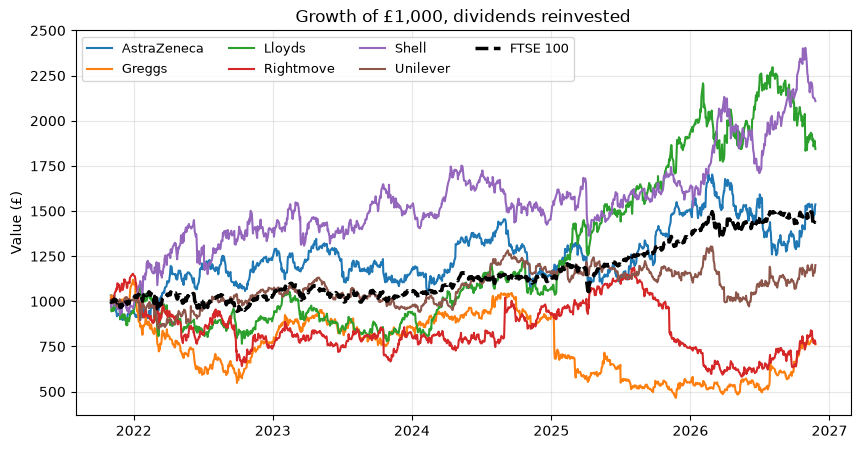

In [5]:
growth = (1 + returns).cumprod() * 1000

fig, ax = plt.subplots()
for col in growth.columns:
    style = {"color": "black", "linewidth": 2.5, "linestyle": "--"} if col == "FTSE 100" else {"linewidth": 1.5}
    ax.plot(growth.index, growth[col], label=col, **style)
ax.set_title("Growth of £1,000, dividends reinvested")
ax.set_ylabel("Value (£)")
ax.legend(ncol=4, fontsize=9)
plt.show()

## 6. Risk and return for each share

- **Annual return** is the compound growth rate (CAGR) over the whole period.
- **Volatility** is the standard deviation of daily returns, scaled up to a year by multiplying by √252.
- **Sharpe ratio** is return above the risk-free rate per unit of volatility. Higher is better.
- **Beta** measures how much a share moves when the FTSE 100 moves 1%. It is the covariance of the share with the market divided by the market's variance.
- **Max drawdown** is the biggest fall from a peak to a later low.

In [6]:
def max_drawdown(series):
    """Largest peak-to-trough fall, as a negative fraction."""
    wealth = (1 + series).cumprod()
    peak = wealth.cummax()
    return (wealth / peak - 1).min()

years = len(returns) / TRADING_DAYS
market_var = market_returns.var()

summary = pd.DataFrame(index=returns.columns)
summary["Annual return"] = (1 + returns).prod() ** (1 / years) - 1
summary["Volatility"] = returns.std() * np.sqrt(TRADING_DAYS)
summary["Sharpe ratio"] = (summary["Annual return"] - RISK_FREE) / summary["Volatility"]
summary["Beta"] = [returns[c].cov(market_returns) / market_var for c in returns.columns]
summary["Max drawdown"] = [max_drawdown(returns[c]) for c in returns.columns]

summary.sort_values("Sharpe ratio", ascending=False).style.format({
    "Annual return": "{:.1%}", "Volatility": "{:.1%}", "Sharpe ratio": "{:.2f}",
    "Beta": "{:.2f}", "Max drawdown": "{:.1%}",
})

,Annual return,Volatility,Sharpe ratio,Beta,Max drawdown
Shell,15.8%,24.3%,0.49,0.91,-22.2%
Lloyds,12.8%,27.4%,0.32,1.42,-29.1%
FTSE 100,7.4%,12.6%,0.27,1.00,-13.4%
AstraZeneca,8.8%,24.9%,0.19,0.98,-27.2%
Unilever,3.7%,19.4%,-0.02,0.53,-25.5%
Rightmove,-5.1%,31.9%,-0.29,0.96,-50.9%
Greggs,-5.2%,31.6%,-0.29,1.03,-58.4%


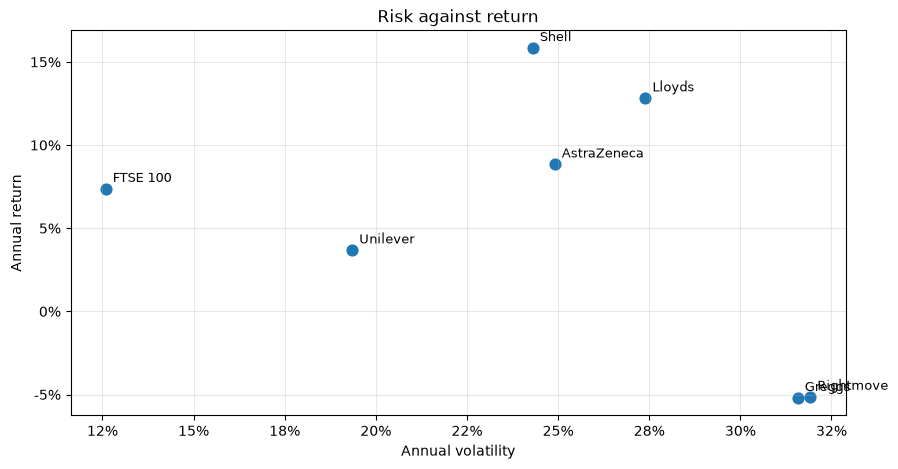

In [7]:
fig, ax = plt.subplots()
ax.scatter(summary["Volatility"], summary["Annual return"], s=60)
for name, row in summary.iterrows():
    ax.annotate(name, (row["Volatility"], row["Annual return"]), xytext=(5, 5), textcoords="offset points", fontsize=9)
ax.set_xlabel("Annual volatility")
ax.set_ylabel("Annual return")
ax.set_title("Risk against return")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
plt.show()

## 7. Correlations

Correlation runs from -1 (always move in opposite directions) to +1 (always move together). Shares with low correlation to each other reduce a portfolio's risk when held together, which is the whole point of diversification.

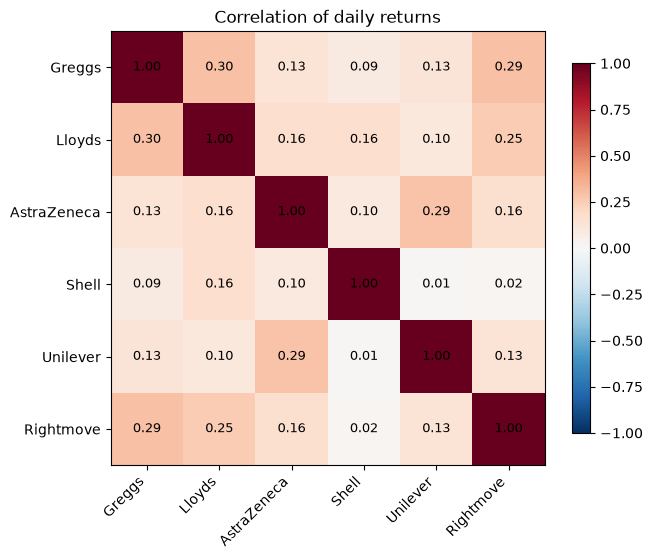

In [8]:
corr = stock_returns.corr()

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
ax.set_title("Correlation of daily returns")
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8)
plt.show()

## 8. Portfolio maths

For a portfolio with weights **w**, the expected annual return is the weighted average of each share's mean return, and the variance is **wᵀΣw**, where Σ is the annualised covariance matrix. Volatility is the square root of that.

Here I use the arithmetic mean of daily returns × 252 as the expected return, which is the usual input for mean-variance optimisation.

In [9]:
mean_returns = stock_returns.mean() * TRADING_DAYS
cov_matrix = stock_returns.cov() * TRADING_DAYS
n = len(stocks)

def portfolio_stats(weights):
    """Return (annual return, annual volatility, Sharpe ratio) for a set of weights."""
    weights = np.array(weights)
    ret = weights @ mean_returns
    vol = np.sqrt(weights @ cov_matrix @ weights)
    return ret, vol, (ret - RISK_FREE) / vol

equal = np.repeat(1 / n, n)
r, v, s = portfolio_stats(equal)
print(f"Equal-weighted portfolio: return {r:.1%}, volatility {v:.1%}, Sharpe {s:.2f}")

Equal-weighted portfolio: return 8.3%, volatility 14.7%, Sharpe 0.29


## 9. 10,000 random portfolios

A quick way to see the shape of the problem: generate random weights (long only, summing to 100%) and plot each portfolio's risk and return.

In [10]:
rng = np.random.default_rng(42)          # fixed seed so the results repeat
n_portfolios = 10_000
weights_sim = rng.dirichlet(np.ones(n), n_portfolios)

sim_ret = weights_sim @ mean_returns.values
sim_vol = np.sqrt(np.einsum("ij,jk,ik->i", weights_sim, cov_matrix.values, weights_sim))
sim_sharpe = (sim_ret - RISK_FREE) / sim_vol

## 10. Efficient frontier

Instead of relying on random guesses, `scipy.optimize.minimize` finds the exact weights for:

- the **minimum-variance portfolio**, the least risky mix possible, and
- the **maximum-Sharpe portfolio**, the best return per unit of risk (the tangency portfolio).

It then traces the frontier by finding the lowest-volatility portfolio for each target return. Weights are kept between 0% and 100% (no short selling).

In [11]:
bounds = [(0, 1)] * n
sums_to_one = {"type": "eq", "fun": lambda w: w.sum() - 1}

def neg_sharpe(w):
    return -portfolio_stats(w)[2]

def volatility(w):
    return portfolio_stats(w)[1]

max_sharpe = minimize(neg_sharpe, equal, bounds=bounds, constraints=[sums_to_one]).x
min_vol = minimize(volatility, equal, bounds=bounds, constraints=[sums_to_one]).x

target_returns = np.linspace(portfolio_stats(min_vol)[0], mean_returns.max(), 40)
frontier_vol = []
for target in target_returns:
    hits_target = {"type": "eq", "fun": lambda w, t=target: portfolio_stats(w)[0] - t}
    result = minimize(volatility, equal, bounds=bounds, constraints=[sums_to_one, hits_target])
    frontier_vol.append(result.fun)

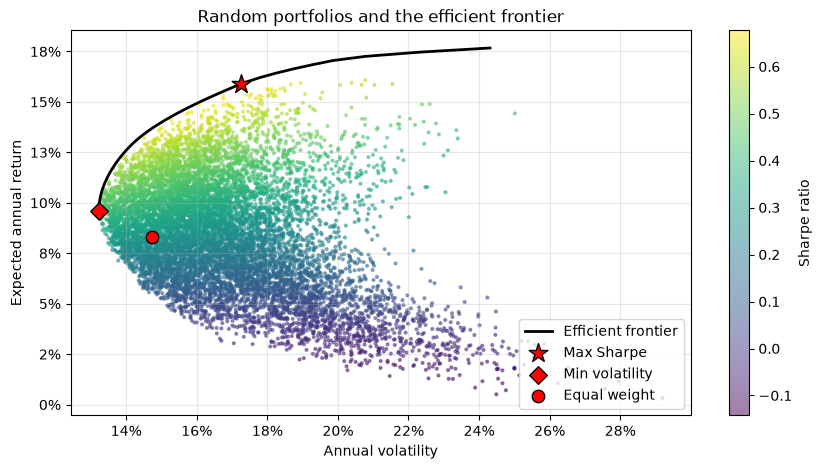

In [12]:
fig, ax = plt.subplots()
pts = ax.scatter(sim_vol, sim_ret, c=sim_sharpe, cmap="viridis", s=4, alpha=0.5)
ax.plot(frontier_vol, target_returns, color="black", linewidth=2, label="Efficient frontier")

for w, label, marker in [(max_sharpe, "Max Sharpe", "*"), (min_vol, "Min volatility", "D"), (equal, "Equal weight", "o")]:
    r, v, _ = portfolio_stats(w)
    ax.scatter(v, r, marker=marker, s=200 if marker == "*" else 80, color="red", edgecolor="black", zorder=3, label=label)

ax.set_xlabel("Annual volatility")
ax.set_ylabel("Expected annual return")
ax.set_title("Random portfolios and the efficient frontier")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
fig.colorbar(pts, ax=ax, label="Sharpe ratio")
ax.legend(loc="lower right")
plt.show()

## 11. The optimal weights

In [13]:
weights_table = pd.DataFrame({
    "Max Sharpe": max_sharpe,
    "Min volatility": min_vol,
    "Equal weight": equal,
}, index=stocks)

stats = pd.DataFrame(
    [portfolio_stats(weights_table[c]) for c in weights_table.columns],
    index=weights_table.columns,
    columns=["Return", "Volatility", "Sharpe ratio"],
).T

display(weights_table.style.format("{:.1%}"))
display(stats.style.format("{:.2f}").format("{:.1%}", subset=pd.IndexSlice[["Return", "Volatility"], :]))

,Max Sharpe,Min volatility,Equal weight
Greggs,0.0%,6.4%,16.7%
Lloyds,28.9%,10.5%,16.7%
AstraZeneca,20.6%,13.0%,16.7%
Shell,50.5%,25.2%,16.7%
Unilever,0.0%,36.9%,16.7%
Rightmove,0.0%,8.1%,16.7%


,Max Sharpe,Min volatility,Equal weight
Return,15.9%,9.6%,8.3%
Volatility,17.2%,13.2%,14.7%
Sharpe ratio,0.69,0.42,0.29


## 12. Limitations

- **The past is not the future.** The optimiser picks whichever shares did best over this window. Five different years could give very different weights.
- **Mean returns are noisy.** Small changes in expected returns swing the weights a lot, which is why the max-Sharpe portfolio often piles into one or two shares.
- **Volatility is not the only risk.** It treats upside and downside moves the same and misses rare crashes, which is why I also report max drawdown.
- **Costs and tax are ignored**, as is the fact that you can't rebalance to exact weights every day.

Possible next steps: use a rolling window to see how the weights change over time, add a cap on any one share's weight, or backtest the max-Sharpe portfolio out of sample.